<a href="https://colab.research.google.com/github/UH-HACKATHON-TEAMN/Hackathon-Town-C/blob/main/Prardhan_EDA_Models.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# Imports and Data Loading
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set plot style for better presentation visuals
sns.set_theme(style="whitegrid")

# Load the training dataset
df_train = pd.read_csv('dataset_C_training.csv')

# Display the shape and the first few rows
print("Training Dataset Shape:", df_train.shape)
display(df_train.head())

Training Dataset Shape: (4756, 31)


,respondent_id,covid_concern,covid_knowledge,behavioral_antiviral_meds,behavioral_avoidance,behavioral_face_mask,behavioral_wash_hands,behavioral_large_gatherings,behavioral_outside_home,behavioral_touch_face,...,census_msa,household_adults,household_children,doctor_recc_covid,opinion_covid_vacc_effective,opinion_covid_risk,opinion_covid_sick_from_vacc,employment_sector,number_chronic_med_conditions,covid_vaccine
0,1,3.0,1.0,0.0,1.0,0.0,1.0,0.0,1.0,1.0,...,"MSA, Principle City",3.0,2.0,0,4,4,2.0,construction,1,0
1,2,2.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,...,Non-MSA,0.0,0.0,0,5,2,1.0,education,0,1
2,3,0.0,2.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,"MSA, Not Principle City",0.0,0.0,0,2,2,5.0,wholesale,3,0
3,4,2.0,2.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,...,"MSA, Not Principle City",1.0,0.0,1,3,3,2.0,NaN,1,1
4,5,1.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,...,"MSA, Not Principle City",0.0,0.0,0,3,2,2.0,wholesale,0,0


--- Missing Values ---
covid_concern                     12
covid_knowledge                   27
behavioral_antiviral_meds         14
behavioral_avoidance              27
behavioral_face_mask               2
behavioral_wash_hands              9
behavioral_large_gatherings       10
behavioral_outside_home           14
behavioral_touch_face             21
child_under_6_months             135
health_worker                    132
health_insurance                1908
education                        228
income_poverty                   748
marital_status                   231
rent_or_own                      329
employment_status                238
household_adults                  39
household_children                39
opinion_covid_sick_from_vacc      90
employment_sector               2330
dtype: int64

--- Target Variable Distribution ---


/tmp/ipykernel_4665/3929643592.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(data=df_train, x='covid_vaccine', palette='viridis')


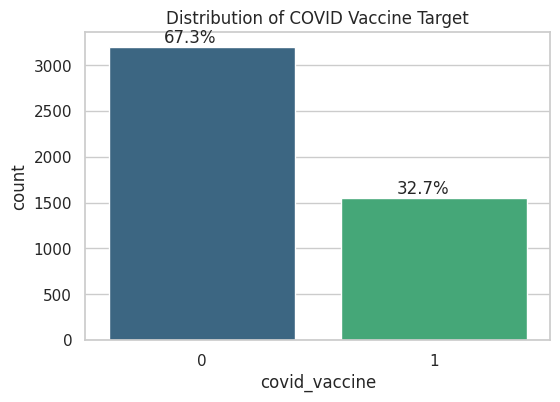

In [2]:
# EDA - Missing Values and Target Distribution
# 1. Check for missing values
print("--- Missing Values ---")
missing_data = df_train.isnull().sum()
print(missing_data[missing_data > 0])

# 2. Visualize the Target Variable
print("\n--- Target Variable Distribution ---")
plt.figure(figsize=(6, 4))
ax = sns.countplot(data=df_train, x='covid_vaccine', palette='viridis')
plt.title('Distribution of COVID Vaccine Target')

# Add percentages
total = len(df_train)
for p in ax.patches:
    percentage = f'{100 * p.get_height() / total:.1f}%'
    x = p.get_x() + p.get_width() / 2 - 0.05
    y = p.get_height()
    ax.annotate(percentage, (x, y), ha='center', va='bottom')

plt.show()

In [3]:
# Data Splitting and Preprocessing Pipeline
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OrdinalEncoder

# 1. Separate features (X) and target (y)
X = df_train.drop(columns=['covid_vaccine', 'respondent_id'])
y = df_train['covid_vaccine']

# 2. Split data for local validation (80% train, 20% validation)
X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, random_state=42)

# 3. Identify column types
categorical_cols = X_train.select_dtypes(include=['object', 'category']).columns
numerical_cols = X_train.select_dtypes(include=['int64', 'float64']).columns

# 4. Create Preprocessing Steps
# Numerical: Fill missing with median
numerical_transformer = SimpleImputer(strategy='median')

# Categorical: Fill missing with mode, then encode text to numbers
categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1))
])

# 5. Bundle everything together
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numerical_transformer, numerical_cols),
        ('cat', categorical_transformer, categorical_cols)
    ])

print("Preprocessing pipeline successfully defined!")
print(f"Numerical columns: {len(numerical_cols)}")
print(f"Categorical columns: {len(categorical_cols)}")

Preprocessing pipeline successfully defined!
Numerical columns: 19
Categorical columns: 10


In [5]:
from xgboost import XGBClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import classification_report, accuracy_score

# init xgb with some basic params
xgb_model = XGBClassifier(
    n_estimators=150,
    learning_rate=0.1,
    max_depth=5,
    random_state=42,
    eval_metric='logloss'
)

# chain preprocessing and model
xgb_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('model', xgb_model)
])

# fit on training data
print("training...")
xgb_pipeline.fit(X_train, y_train)

# get val preds
val_preds = xgb_pipeline.predict(X_val)

# check baseline metrics before applying cost function
print(f"accuracy: {accuracy_score(y_val, val_preds):.4f}")
print(classification_report(y_val, val_preds))

training...
accuracy: 0.7847
              precision    recall  f1-score   support

           0       0.81      0.89      0.85       653
           1       0.70      0.56      0.62       299

    accuracy                           0.78       952
   macro avg       0.76      0.72      0.73       952
weighted avg       0.78      0.78      0.78       952



In [6]:
# custom financial cost metric using AI-estimated probabilities
import numpy as np

COST_VACCINE = 1500
COST_HOSPITAL = 41000

def eval_town_cost(y_true, y_pred, X_data):
    # 1. VACCINE COSTS
    # cost of sending vaccines (paid whether they use it or ruin it)
    cost_vax_sent = np.sum(y_pred == 1) * COST_VACCINE

    # local law penalty: town pays $1500 if someone wanted it but we didn't send it (false negative)
    cost_law_penalty = np.sum((y_true == 1) & (y_pred == 0)) * COST_VACCINE

    total_vax_cost = cost_vax_sent + cost_law_penalty

    # 2. HOSPITALISATION COSTS (AI Estimated Rule based on assignment brief)
    # identify who actually got vaccinated (they wanted it AND we sent it)
    is_vaccinated = (y_true == 1) & (y_pred == 1)

    # base risk of 2%, plus 3% per chronic condition
    chronic_conditions = X_data['number_chronic_med_conditions'].fillna(0).astype(float)
    base_hosp_prob = 0.02 + (0.03 * chronic_conditions)

    # cap probability at 100%
    base_hosp_prob = np.clip(base_hosp_prob, 0, 1.0)

    # apply 90% risk reduction for vaccinated people
    final_hosp_prob = np.where(is_vaccinated, base_hosp_prob * 0.1, base_hosp_prob)

    # calculate expected hospital cost
    total_hosp_cost = np.sum(final_hosp_prob * COST_HOSPITAL)

    return total_vax_cost + total_hosp_cost

# check cost at default 0.5 probability threshold
base_cost = eval_town_cost(y_val, val_preds, X_val)
print(f"default cost (0.5 threshold): ${base_cost:,.2f}")

# loop through thresholds to find the absolute cheapest setup for the town
probs = xgb_pipeline.predict_proba(X_val)[:, 1]
best_cost = float('inf')
best_t = 0.5

for t in np.arange(0.05, 0.95, 0.05):
    t_preds = (probs >= t).astype(int)
    cost = eval_town_cost(y_val, t_preds, X_val)
    if cost < best_cost:
        best_cost = cost
        best_t = t

print(f"lowest possible cost: ${best_cost:,.2f} at threshold {best_t:.2f}")

default cost (0.5 threshold): $1,543,042.00
lowest possible cost: $1,538,527.00 at threshold 0.60


/tmp/ipykernel_4665/3005434107.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=importance_df.head(10), x='importance', y='feature', palette='viridis')


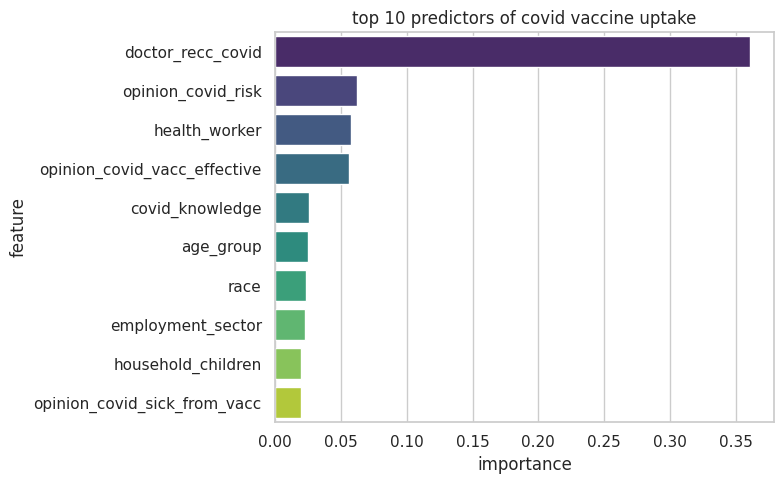

In [7]:
# explainable ai (xai) - feature importance for the presentation
import matplotlib.pyplot as plt
import pandas as pd

# extract trained model from pipeline
trained_xgb = xgb_pipeline.named_steps['model']

# column transformer outputs numerical first, then categorical.
# we combine the lists to match the model's exact expected order
feature_names = numerical_cols.tolist() + categorical_cols.tolist()

# map importances to feature names
importance_df = pd.DataFrame({
    'feature': feature_names,
    'importance': trained_xgb.feature_importances_
}).sort_values(by='importance', ascending=False)

# plot top 10 drivers for vaccine uptake
plt.figure(figsize=(8, 5))
sns.barplot(data=importance_df.head(10), x='importance', y='feature', palette='viridis')
plt.title('top 10 predictors of covid vaccine uptake')
plt.tight_layout()
plt.show()

In [8]:
# test set predictions using tuned 0.60 threshold
# load test set
df_test = pd.read_csv('dataset_C_testing.csv')

# generate probabilities with trained pipeline
test_probs = xgb_pipeline.predict_proba(df_test.drop(columns=['respondent_id'], errors='ignore'))[:, 1]

# apply cost-optimized 0.60 threshold
test_preds = (test_probs >= 0.60).astype(int)

# format submission
submission = pd.DataFrame({
    'respondent_id': df_test['respondent_id'],
    'covid_vaccine_prob': np.round(test_probs, 4),
    'covid_vaccine': test_preds
})

# save output
submission.to_csv('Prardhan_XGBoost_predictions.csv', index=False)
print("test predictions saved successfully!")
display(submission.head())

test predictions saved successfully!


,respondent_id,covid_vaccine_prob,covid_vaccine
0,4757,0.1663,0
1,4758,0.2838,0
2,4759,0.1151,0
3,4760,0.3102,0
4,4761,0.0134,0


In [9]:
# train random forest & lightgbm + compare all 3 models on cost
from sklearn.ensemble import RandomForestClassifier
from lightgbm import LGBMClassifier
import pandas as pd
import numpy as np

# define new models
rf_model = RandomForestClassifier(n_estimators=150, max_depth=8, random_state=42)
lgb_model = LGBMClassifier(n_estimators=150, max_depth=5, learning_rate=0.1, random_state=42, verbose=-1)

# create pipelines using our existing preprocessor
rf_pipeline = Pipeline(steps=[('preprocessor', preprocessor), ('model', rf_model)])
lgb_pipeline = Pipeline(steps=[('preprocessor', preprocessor), ('model', lgb_model)])

# dict of all models
models = {
    'XGBoost': xgb_pipeline,  # already trained in cell 4
    'Random Forest': rf_pipeline,
    'LightGBM': lgb_pipeline
}

results = []

for name, pipe in models.items():
    if name != 'XGBoost':
        print(f"training {name}...")
        pipe.fit(X_train, y_train)

    # get val preds & raw probabilities
    val_preds_def = pipe.predict(X_val)
    probs = pipe.predict_proba(X_val)[:, 1]

    acc = accuracy_score(y_val, val_preds_def)
    def_cost = eval_town_cost(y_val, val_preds_def, X_val)

    # optimize threshold for lowest cost
    best_c = float('inf')
    best_t = 0.5
    for t in np.arange(0.05, 0.95, 0.05):
        t_preds = (probs >= t).astype(int)
        cost = eval_town_cost(y_val, t_preds, X_val)
        if cost < best_c:
            best_c = cost
            best_t = round(t, 2)

    results.append({
        'Model': name,
        'Val Accuracy': f"{acc:.4f}",
        'Default Cost (0.5)': f"${def_cost:,.2f}",
        'Optimal Threshold': best_t,
        'Lowest Town Cost': f"${best_c:,.2f}"
    })

# display summary comparison dataframe
df_comparison = pd.DataFrame(results)
display(df_comparison)

training Random Forest...
training LightGBM...


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


,Model,Val Accuracy,Default Cost (0.5),Optimal Threshold,Lowest Town Cost
0,XGBoost,0.7847,"$1,543,042.00",0.6,"$1,538,527.00"
1,Random Forest,0.7847,"$1,537,981.00",0.5,"$1,537,981.00"
2,LightGBM,0.7742,"$1,555,684.00",0.6,"$1,539,634.00"


In [10]:
# fine-tuning xgboost to boost accuracy & lower town cost
from sklearn.model_selection import ParameterGrid

# search space for key params
param_grid = {
    'max_depth': [3, 5, 7],
    'learning_rate': [0.03, 0.05, 0.1],
    'n_estimators': [100, 200],
    'scale_pos_weight': [1, 2] # handle 67/33 target imbalance
}

best_overall_cost = float('inf')
best_acc = 0
best_params = {}
best_thresh = 0.5
best_tuned_pipe = None

print("tuning xgboost hyperparams...")
for params in ParameterGrid(param_grid):
    # build pipe with candidate params
    tuned_xgb = XGBClassifier(**params, random_state=42, eval_metric='logloss')
    tuned_pipe = Pipeline(steps=[('preprocessor', preprocessor), ('model', tuned_xgb)])

    tuned_pipe.fit(X_train, y_train)

    acc = accuracy_score(y_val, tuned_pipe.predict(X_val))
    probs = tuned_pipe.predict_proba(X_val)[:, 1]

    # evaluate threshold cost
    for t in np.arange(0.1, 0.9, 0.05):
        t_preds = (probs >= t).astype(int)
        cost = eval_town_cost(y_val, t_preds, X_val)

        if cost < best_overall_cost:
            best_overall_cost = cost
            best_acc = acc
            best_params = params
            best_thresh = round(t, 2)
            best_tuned_pipe = tuned_pipe

print("\n--- tuning results ---")
print(f"tuned xgboost val accuracy: {best_acc:.4f}")
print(f"new lowest town cost: ${best_overall_cost:,.2f} at threshold {best_thresh}")
print("best params:", best_params)

tuning xgboost hyperparams...

--- tuning results ---
tuned xgboost val accuracy: 0.7878
new lowest town cost: $1,521,016.00 at threshold 0.6
best params: {'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 100, 'scale_pos_weight': 1}


In [11]:
# update test set predictions with best tuned xgboost model
test_probs_tuned = best_tuned_pipe.predict_proba(df_test.drop(columns=['respondent_id'], errors='ignore'))[:, 1]

# apply optimal 0.60 threshold from tuning run
test_preds_tuned = (test_probs_tuned >= 0.60).astype(int)

# create updated submission dataframe
submission_tuned = pd.DataFrame({
    'respondent_id': df_test['respondent_id'],
    'covid_vaccine_prob': np.round(test_probs_tuned, 4),
    'covid_vaccine': test_preds_tuned
})

# overwrite predictions file
submission_tuned.to_csv('Prardhan_XGBoost_predictions.csv', index=False)
print("updated predictions exported successfully!")
display(submission_tuned.head())

updated predictions exported successfully!


,respondent_id,covid_vaccine_prob,covid_vaccine
0,4757,0.1569,0
1,4758,0.1995,0
2,4759,0.1165,0
3,4760,0.3401,0
4,4761,0.0417,0


In [12]:

final_sub = submission_tuned[['respondent_id', 'covid_vaccine']]


file_name = 'challenge_submission_group_X_order_Y.csv'

# export
final_sub.to_csv(file_name, index=False)
print(f"saved {file_name} with exactly 2 columns!")
display(final_sub.head(2))

saved challenge_submission_group_X_order_Y.csv with exactly 2 columns!


,respondent_id,covid_vaccine
0,4757,0
1,4758,0


In [15]:
import pandas as pd
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OrdinalEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier



# 2. Define features and preprocessor
numeric_cols = X_train.select_dtypes(include=['int64', 'float64']).columns
categorical_cols = X_train.select_dtypes(include=['object', 'category']).columns

preprocessor = ColumnTransformer(
    transformers=[
        ('num', SimpleImputer(strategy='median'), numeric_cols),
        ('cat', Pipeline(steps=[
            ('imputer', SimpleImputer(strategy='most_frequent')),
            ('encoder', OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1))
        ]), categorical_cols)
    ]
)

X_test_clean = df_test.drop(columns=['respondent_id'], errors='ignore')

# --- MODEL 1: Tuned XGBoost (Order 1) ---
xgb_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('model', XGBClassifier(max_depth=3, n_estimators=100, learning_rate=0.1, random_state=42))
])
xgb_pipeline.fit(X_train, y_train)
xgb_probs = xgb_pipeline.predict_proba(X_test_clean)[:, 1]
xgb_preds = (xgb_probs >= 0.60).astype(int) # using optimal threshold 0.60

sub_xgb = pd.DataFrame({
    'respondent_id': df_test['respondent_id'],
    'covid_vaccine': xgb_preds
})
sub_xgb.to_csv('challenge_submission_group_N_order_1.csv', index=False)

# --- MODEL 2: Random Forest (Order 2) ---
rf_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('model', RandomForestClassifier(random_state=42))
])
rf_pipeline.fit(X_train, y_train)
rf_preds = rf_pipeline.predict(X_test_clean) # default threshold 0.5

sub_rf = pd.DataFrame({
    'respondent_id': df_test['respondent_id'],
    'covid_vaccine': rf_preds
})
sub_rf.to_csv('challenge_submission_group_N_order_2.csv', index=False)

# --- MODEL 3: LightGBM (Order 3) ---
lgb_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('model', LGBMClassifier(random_state=42, verbose=-1))
])
lgb_pipeline.fit(X_train, y_train)
lgb_probs = lgb_pipeline.predict_proba(X_test_clean)[:, 1]
lgb_preds = (lgb_probs >= 0.60).astype(int) # using optimal threshold 0.60

sub_lgb = pd.DataFrame({
    'respondent_id': df_test['respondent_id'],
    'covid_vaccine': lgb_preds
})
sub_lgb.to_csv('challenge_submission_group_N_order_3.csv', index=False)

print("Successfully generated and exported all 3 submission files!")

Successfully generated and exported all 3 submission files!


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
